Ecuaciones de regresion multiple

In [ ]:
import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import seaborn as sns 
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

In [94]:
def load_df_from_file(name):
    try:
        df = pd.read_csv(name, sep="\t")
        print("file loaded with columns : ")
        print(df.columns)
        return df
    except FileNotFoundError:
        print("File not found. Please ensure '"+name+"' is in the current directory.")
        return None

name = 'datos.csv'
datos = load_df_from_file(name) 
datos.head()

file loaded with columns : 
Index(['fecha', 'temperatura', 'humedad', 'pms7003_pm2_5', 'hpma_pm2_5', 'co', 'o3', 'PM2.5', 'CO_1', 'O3_1'], dtype='str')


,fecha,temperatura,humedad,pms7003_pm2_5,hpma_pm2_5,co,o3,PM2.5,CO_1,O3_1
0,2026-06-09 12:00:00,19.915147,65.186605,27.736508,18.963492,3.231688,0.011407,14.97,0.31,28.36
1,2026-06-09 13:00:00,21.295723,60.953508,25.633333,18.066667,2.974421,0.021877,17.18,0.30,35.86
2,2026-06-09 14:00:00,19.624773,67.830865,24.633333,16.708333,2.867090,0.034624,25.75,0.28,31.09
3,2026-06-09 15:00:00,19.728193,67.101857,25.258333,17.066667,2.939729,0.068174,11.07,0.42,28.12
4,2026-06-09 16:00:00,18.601375,73.504601,30.666667,22.866667,3.171149,0.035565,26.50,0.47,27.68


**corrigiendo O3 ppb a ppm**

In [95]:
datos['O3_1'] = datos['O3_1'] /1000

datos.loc[datos['co'] >= 20, 'co'] =0
datos.head()

,fecha,temperatura,humedad,pms7003_pm2_5,hpma_pm2_5,co,o3,PM2.5,CO_1,O3_1
0,2026-06-09 12:00:00,19.915147,65.186605,27.736508,18.963492,3.231688,0.011407,14.97,0.31,0.02836
1,2026-06-09 13:00:00,21.295723,60.953508,25.633333,18.066667,2.974421,0.021877,17.18,0.30,0.03586
2,2026-06-09 14:00:00,19.624773,67.830865,24.633333,16.708333,2.867090,0.034624,25.75,0.28,0.03109
3,2026-06-09 15:00:00,19.728193,67.101857,25.258333,17.066667,2.939729,0.068174,11.07,0.42,0.02812
4,2026-06-09 16:00:00,18.601375,73.504601,30.666667,22.866667,3.171149,0.035565,26.50,0.47,0.02768


pms7003 pm2_5

In [136]:

datos_completo = datos[(datos['temperatura'].notna()) & (datos['humedad'].notna())  & (datos['pms7003_pm2_5'].notna())  & (datos['PM2.5'].notna())] 
datos_completo = datos_completo[['temperatura','humedad','pms7003_pm2_5','PM2.5']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'PM2.5'
base_features = ['temperatura','humedad','pms7003_pm2_5']

# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE','MAE', 'Interseccion_b']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                                                                           Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE  Interseccion_b
0                                                          temperatura, humedad, pms7003_pm2_5, temperatura*pms7003_pm2_5, humedad*pms7003_pm2_5  0.3927       0.3904  5.0587  3.8790         46.9922
1                                     temperatura, humedad, pms7003_pm2_5, temperatura*humedad, temperatura*pms7003_pm2_5, humedad*pms7003_pm2_5  0.3929       0.3901  5.0578  3.8759         50.0706
2                       temperatura, humedad, pms7003_pm2_5, temperatura*humedad*pms7003_pm2_5, temperatura*pms7003_pm2_5, humedad*pms7003_pm2_5  0.3928       0.3900  5.0584  3.8780         46.7951
3  temperatura, humedad, pms7003_pm2_5, temperatura*humedad*pms7003_pm2_5, temperatura*humedad, temperatura*pms7003_pm2_5, humedad*pms7003_pm2_5  

# graficando la ecuacion PMS7003 prom horarios

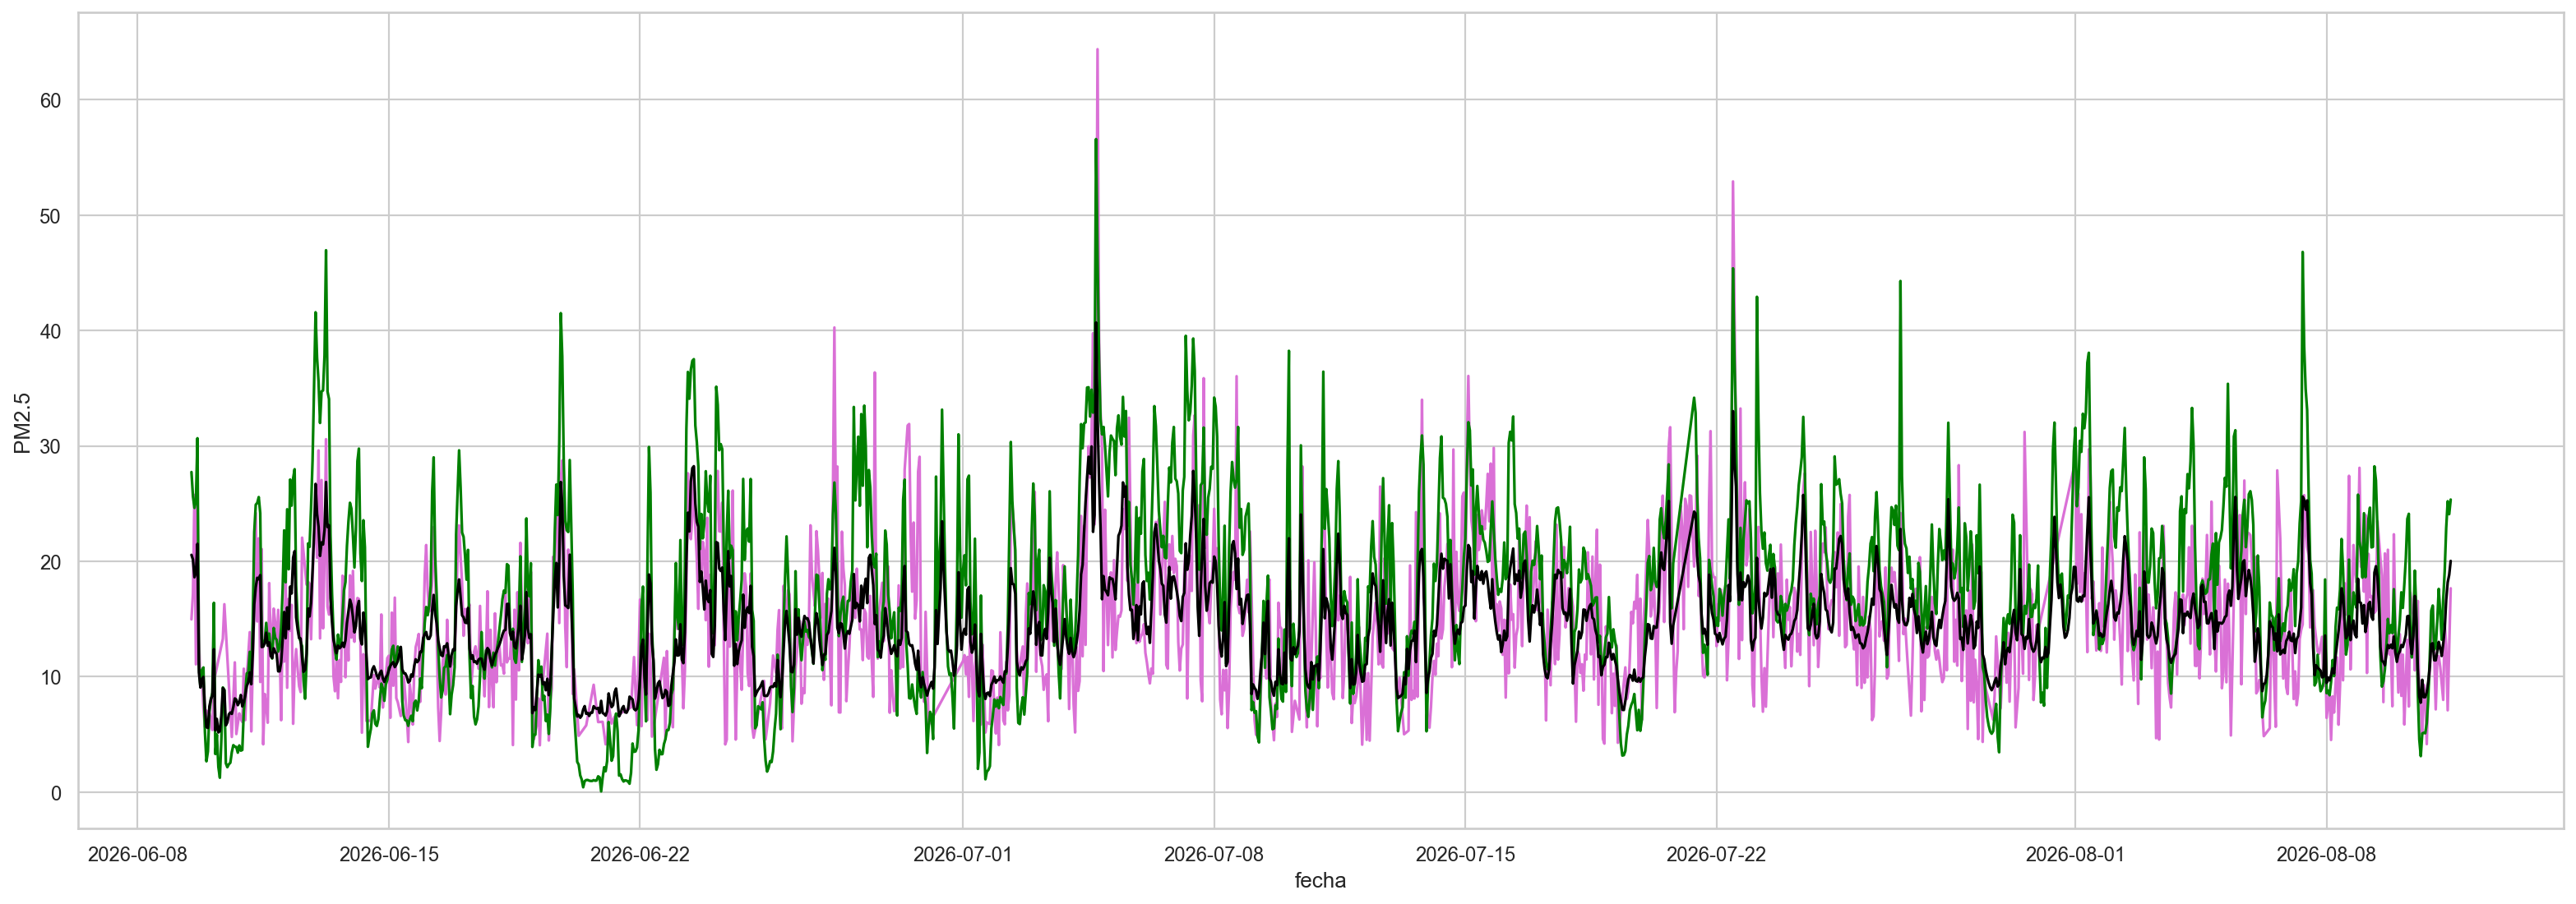

In [135]:
datos_completo = datos.copy()
datos_completo['pm25_corr2'] = 46.9922-1.1641*datos_completo['temperatura']-0.2919*datos_completo['humedad']-1.5371*datos_completo['pms7003_pm2_5']+0.0681*datos_completo['temperatura']*datos_completo['pms7003_pm2_5']+0.0115*datos_completo['humedad']*datos_completo['pms7003_pm2_5']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['PM2.5'],  color='orchid')
sns.lineplot(ax=ax,data=datos_completo['pms7003_pm2_5'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['pm25_corr2'],  color='black')
# Mostrar el gráfico
plt.show()

#  hpma pm2_5

In [137]:
datos_dia =datos[(datos['temperatura'].notna()) & (datos['humedad'].notna())  & (datos['hpma_pm2_5'].notna())  & (datos['PM2.5'].notna())] 
datos_completo = datos_dia[['temperatura','humedad','hpma_pm2_5','PM2.5']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'PM2.5'
base_features = ['temperatura','humedad','hpma_pm2_5']


# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                                                               Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0  temperatura, humedad, hpma_pm2_5, temperatura*humedad*hpma_pm2_5, temperatura*humedad, temperatura*hpma_pm2_5, humedad*hpma_pm2_5  0.4431       0.4402  4.8441  3.7435
1              temperatura, humedad, temperatura*humedad*hpma_pm2_5, temperatura*humedad, temperatura*hpma_pm2_5, humedad*hpma_pm2_5  0.4421       0.4395  4.8486  3.7483
2                                  temperatura, humedad, temperatura*humedad*hpma_pm2_5, temperatura*humedad, temperatura*hpma_pm2_5  0.4414       0.4393  4.8516  3.7551
3                      temperatura, humedad, hpma_pm2_5, temperatura*humedad*hpma_pm2_5, temperatura*humedad, temperatura*hpma_pm2_5  0.4416       0.4391  4.8505  3.7524
4                                                                temperatura, temperatur

# graficando correcion pm2.5 HPMA115.. prom hora

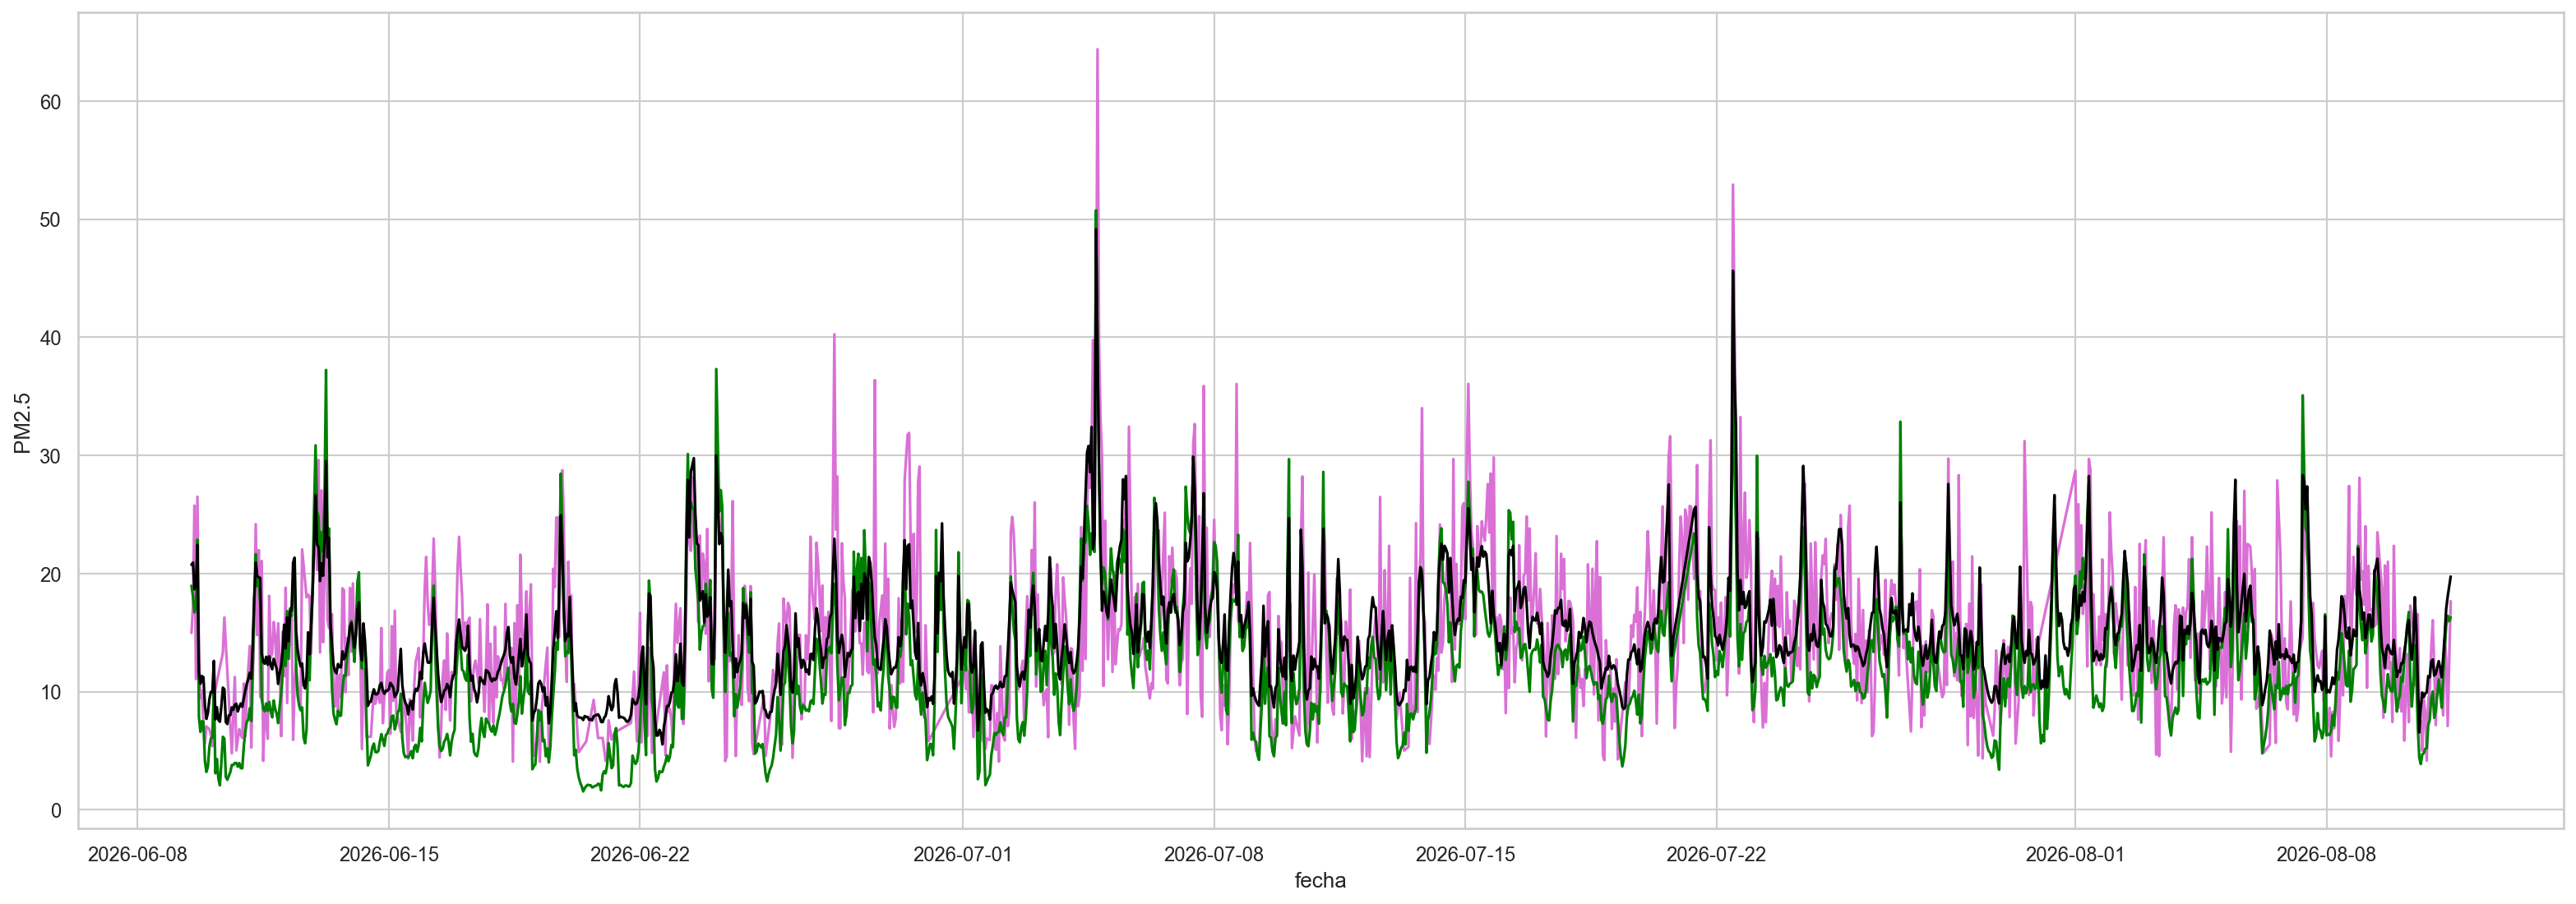

In [140]:
datos_completo = datos.copy()
datos_completo['pm25_corr2'] = 44.5457-1.9093*datos_completo['temperatura']-0.4466*datos_completo['humedad']-1.9204*datos_completo['hpma_pm2_5']-0.0015*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['hpma_pm2_5']+0.0217*datos_completo['temperatura']*datos_completo['humedad']+0.1473*datos_completo['temperatura']*datos_completo['hpma_pm2_5']+0.0266*datos_completo['humedad']*datos_completo['hpma_pm2_5']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['PM2.5'],  color='orchid')
sns.lineplot(ax=ax,data=datos_completo['hpma_pm2_5'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['pm25_corr2'],  color='black')
# Mostrar el gráfico
plt.show()

## CO

In [142]:

datos_completo = datos[(datos['temperatura'].notna()) & (datos['humedad'].notna())  & (datos['co'].notna())  & (datos['CO_1'].notna())] 
datos_completo = datos_completo[['temperatura','humedad','co','CO_1']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'CO_1'
base_features = ['temperatura','humedad','co']

# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                               Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0  temperatura, humedad, co, temperatura*humedad*co, temperatura*humedad, temperatura*co, humedad*co  0.4957       0.4932  0.0698  0.0543
1                       temperatura, humedad, co, temperatura*humedad*co, temperatura*co, humedad*co  0.4862       0.4840  0.0704  0.0550
2           temperatura, co, temperatura*humedad*co, temperatura*humedad, temperatura*co, humedad*co  0.4739       0.4717  0.0713  0.0559
3                          temperatura, humedad, co, temperatura*humedad, temperatura*co, humedad*co  0.4717       0.4695  0.0714  0.0562
4                                temperatura, co, temperatura*humedad*co, temperatura*co, humedad*co  0.4710       0.4692  0.0714  0.0559

Ecuación del mejor modelo:
b (Intersección) = -1.4138
m (Coeficientes) = {'temperatura': np.float64(0.0582), 

# graficando correcion CO prom hora

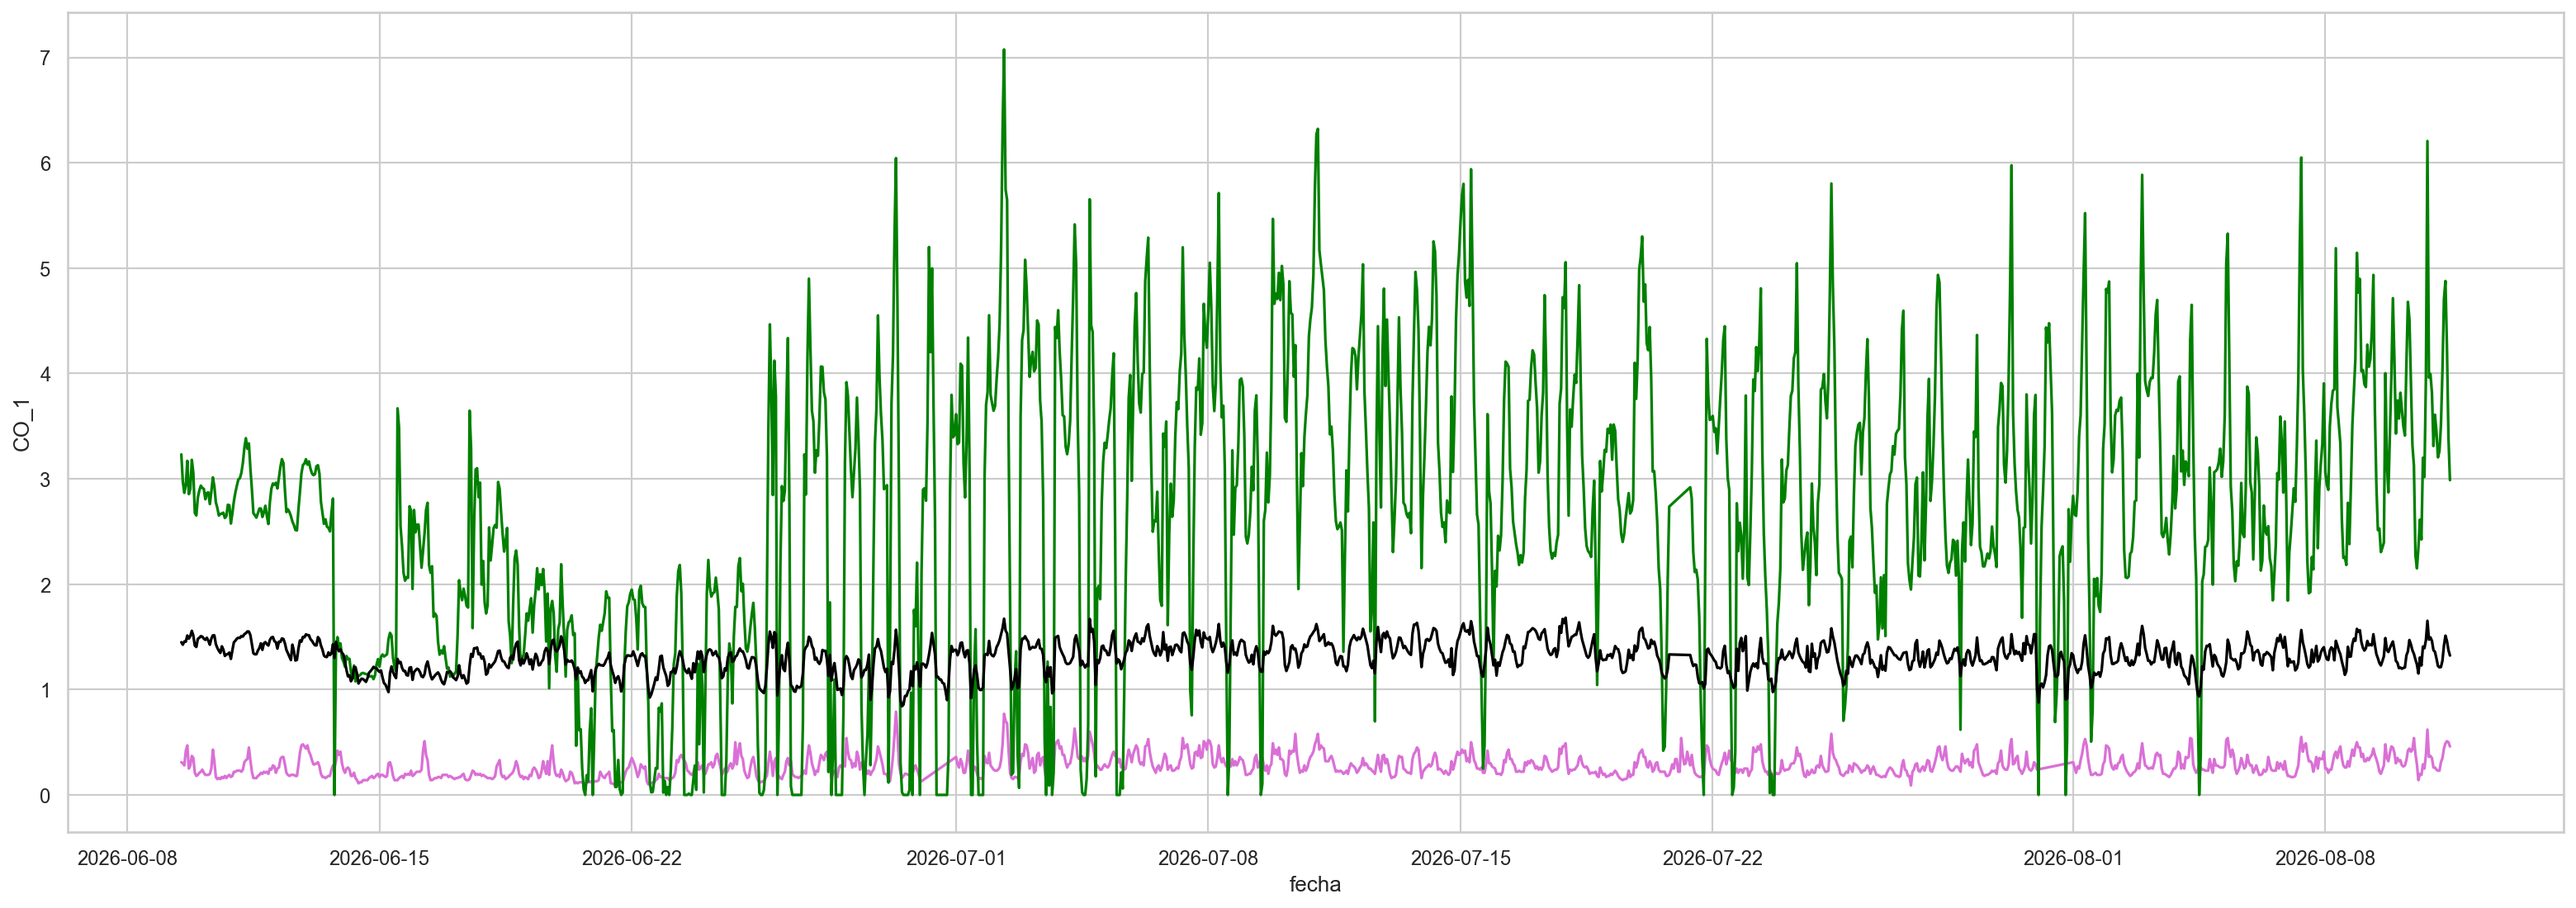

In [143]:
datos_completo = datos.copy()
datos_completo['co_corr2'] = -1.4138+0.0582*datos_completo['temperatura']+0.0147*datos_completo['humedad']+0.6786*datos_completo['co']+0.0003*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['co']+0.0004*datos_completo['temperatura']*datos_completo['humedad']-0.0272*datos_completo['temperatura']*datos_completo['co']-0.007*datos_completo['humedad']*datos_completo['co']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['CO_1'],  color='orchid')
sns.lineplot(ax=ax,data=datos_completo['co'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['co_corr2'],  color='black')
# Mostrar el gráfico
plt.show()

# o3

In [144]:

datos_completo = datos[(datos['temperatura'].notna()) & (datos['humedad'].notna())  & (datos['o3'].notna())  & (datos['O3_1'].notna())] 
datos_completo = datos_completo[['temperatura','humedad','o3','O3_1']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'O3_1'
base_features = ['temperatura','humedad','o3']

# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                               Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0              temperatura, humedad, o3, temperatura*humedad*o3, temperatura*humedad, temperatura*o3  0.7495       0.7484  0.0079  0.0063
1  temperatura, humedad, o3, temperatura*humedad*o3, temperatura*humedad, temperatura*o3, humedad*o3  0.7496       0.7484  0.0079  0.0063
2      temperatura, humedad, temperatura*humedad*o3, temperatura*humedad, temperatura*o3, humedad*o3  0.7494       0.7483  0.0079  0.0063
3                  temperatura, humedad, temperatura*humedad*o3, temperatura*humedad, temperatura*o3  0.7490       0.7481  0.0079  0.0063
4                  temperatura, humedad, o3, temperatura*humedad*o3, temperatura*humedad, humedad*o3  0.7488       0.7478  0.0079  0.0063

Ecuación del mejor modelo:
b (Intersección) = -0.1078
m (Coeficientes) = {'temperatura': np.float64(0.0082), 

# graficando correncion o3 prom hora

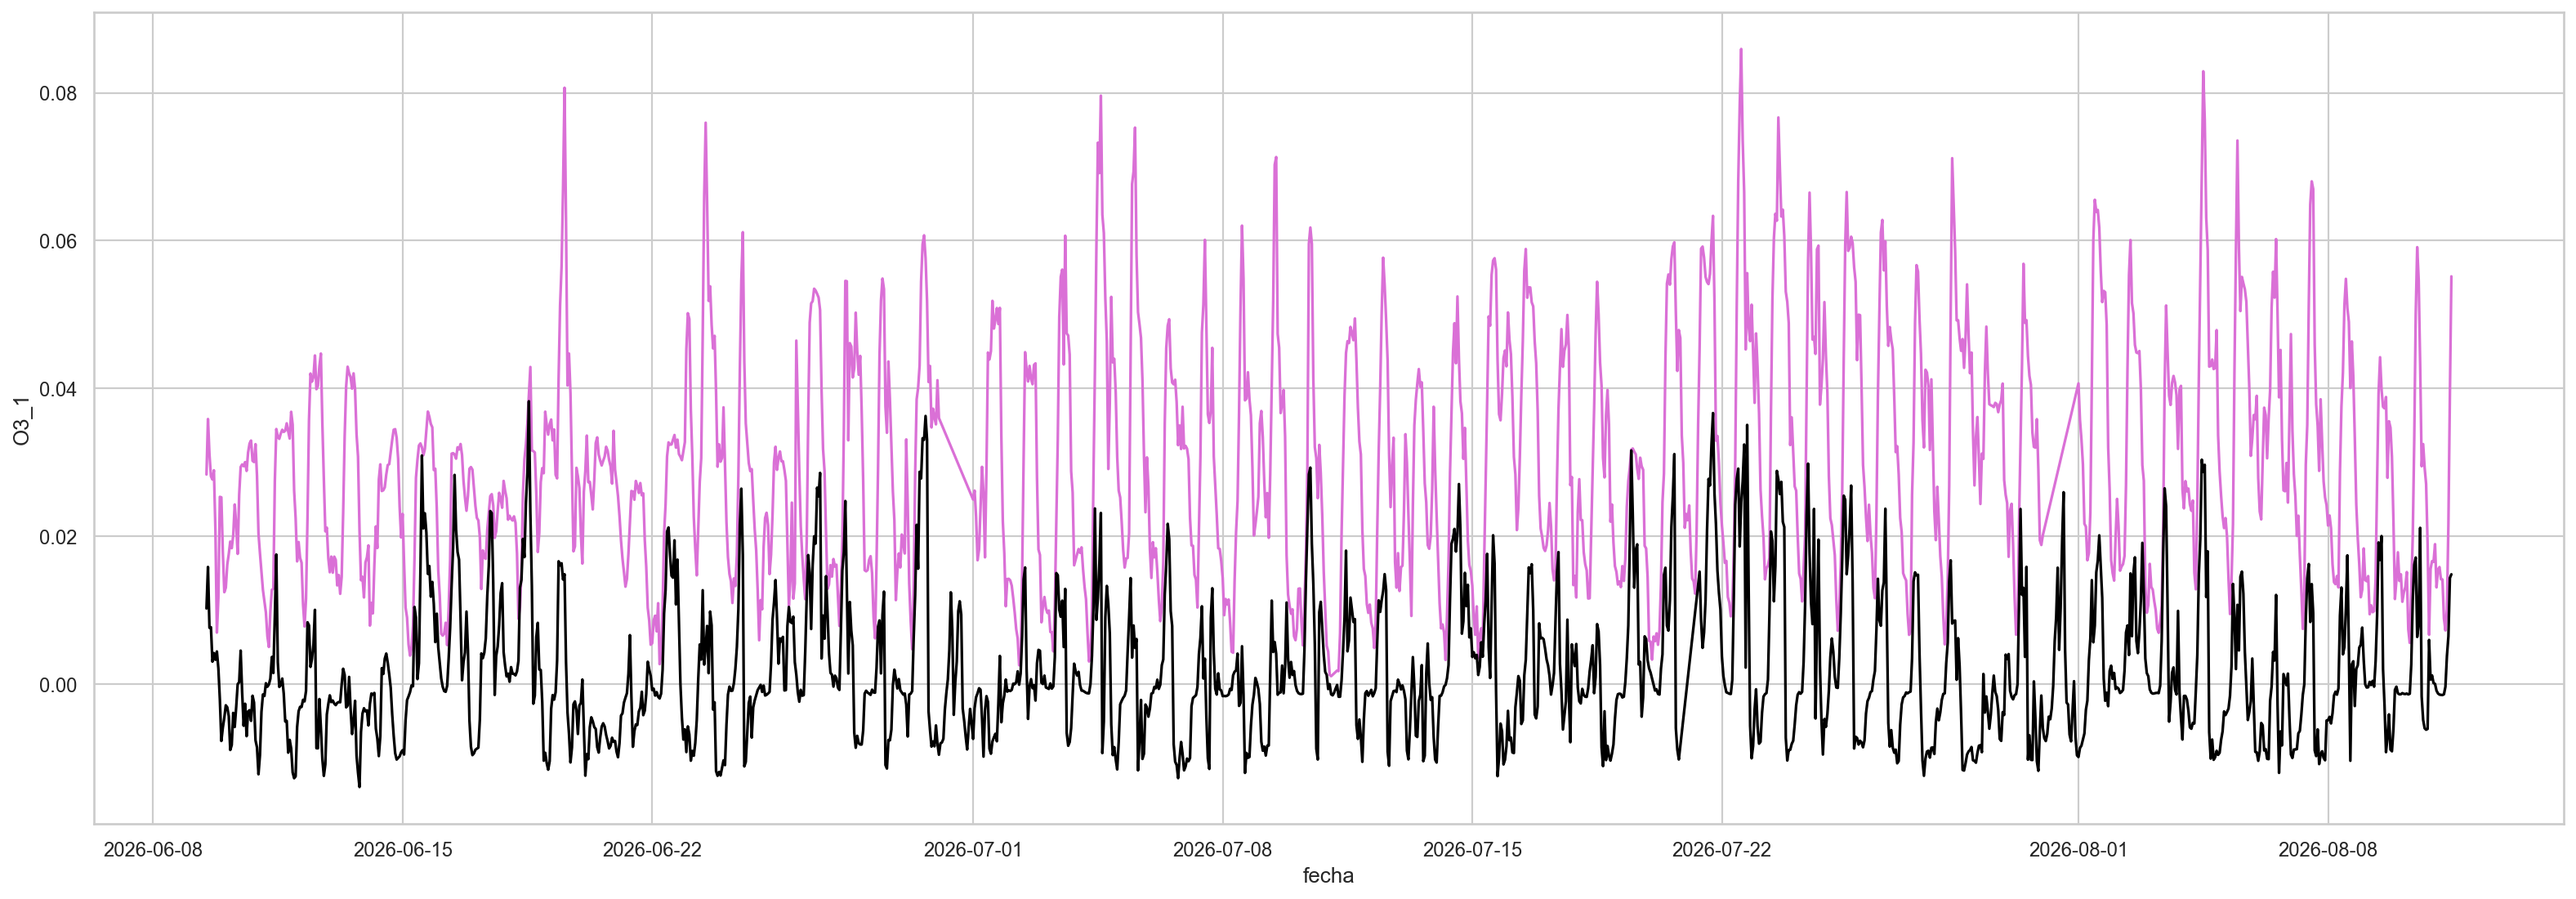

In [147]:
datos_completo = datos.copy()
datos_completo['o3_corr2'] = -0.1078+0.0082*datos_completo['temperatura']+0.0013*datos_completo['humedad']+.015*datos_completo['o3']+0.0*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['o3']-.0001*datos_completo['temperatura']*datos_completo['humedad']-0.0016*datos_completo['temperatura']*datos_completo['o3']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['O3_1'],  color='orchid')

#sns.lineplot(ax=ax,data=datos_completo['o3'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['o3_corr2'],  color='black')
# Mostrar el gráfico
plt.show()

# **datos resampleados a dias**

In [149]:
if 'fecha' in datos.columns:
    datos['fecha'] = pd.to_datetime(datos['fecha'], errors='coerce')
    datos= datos.set_index('fecha')
datos_completo = datos.resample('D').mean().fillna(np.nan).reset_index()
datos_completo = datos_completo[(datos_completo['temperatura'].notna()) & (datos_completo['humedad'].notna())  & (datos_completo['pms7003_pm2_5'].notna())  & (datos_completo['PM2.5'].notna())] 


In [150]:
datos_dias = datos_completo.copy()
datos_completo.head()

,fecha,temperatura,humedad,pms7003_pm2_5,hpma_pm2_5,co,o3,PM2.5,CO_1,O3_1
0,2026-06-09,18.687594,72.445159,15.564848,11.176124,2.944006,0.138166,13.473636,0.300833,0.024005
1,2026-06-10,18.579510,71.004770,5.036806,4.303125,2.781320,0.681758,8.356923,0.203750,0.024649
2,2026-06-11,19.009585,70.844407,14.942361,10.671181,2.893888,0.552144,12.829130,0.237917,0.024147
3,2026-06-12,18.094871,73.376813,20.738194,13.802431,2.876859,0.547232,14.495000,0.287500,0.027251
4,2026-06-13,17.439627,76.245751,24.573264,16.192708,2.440781,0.484779,16.010417,0.287083,0.025362


In [ ]:
#datos_completo.to_csv('datos_hpmapm2.5.csv')

pms7003

In [151]:

datos_completo = datos_completo[['temperatura','humedad','pms7003_pm2_5','PM2.5']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'PM2.5'
base_features = ['temperatura','humedad','pms7003_pm2_5']


# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                        Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0               temperatura*humedad*pms7003_pm2_5, temperatura*humedad, humedad*pms7003_pm2_5  0.7779       0.7666  1.6315  1.1604
1                                                          humedad, temperatura*pms7003_pm2_5  0.7722       0.7646  1.6522  1.1285
2                     pms7003_pm2_5, temperatura*humedad*pms7003_pm2_5, humedad*pms7003_pm2_5  0.7757       0.7643  1.6393  1.1337
3              temperatura, humedad, temperatura*humedad*pms7003_pm2_5, humedad*pms7003_pm2_5  0.7787       0.7635  1.6283  1.1745
4  temperatura, temperatura*humedad*pms7003_pm2_5, temperatura*humedad, humedad*pms7003_pm2_5  0.7787       0.7634  1.6284  1.1652

Ecuación del mejor modelo:
b (Intersección) = 23.843
m (Coeficientes) = {'temperatura*humedad*pms7003_pm2_5': np.float64(0.0014), 'temperatura*humedad'

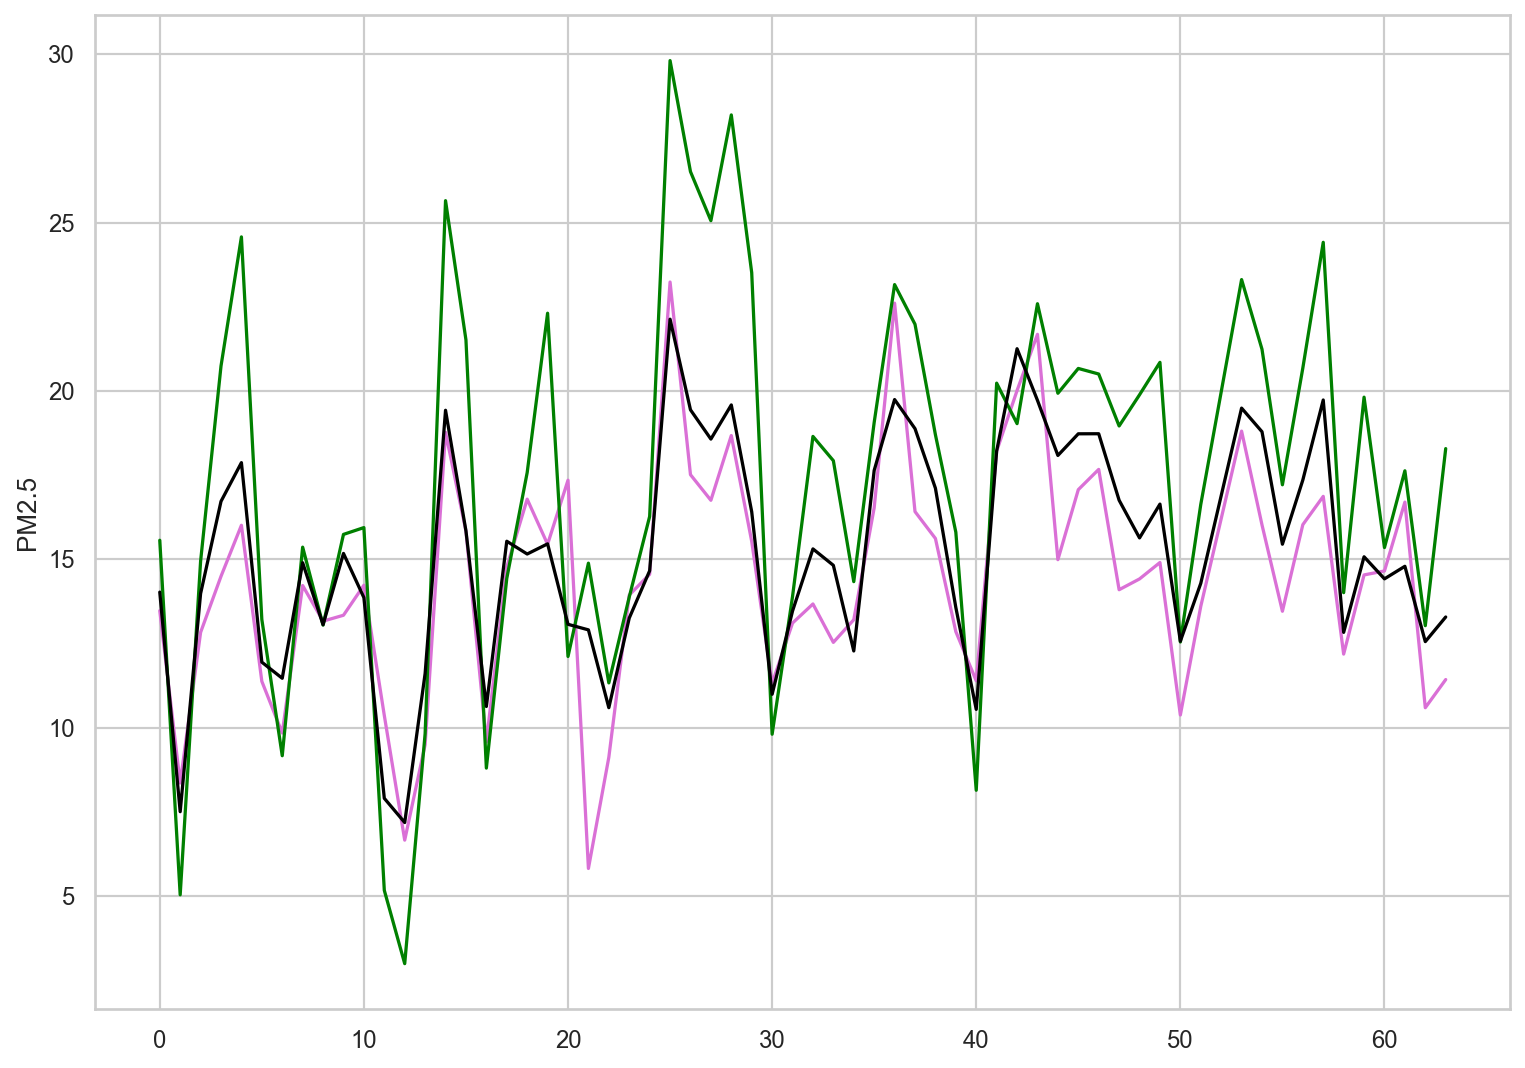

In [152]:
datos_completo['pm25corr2'] = 23.843+0.0014*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['pms7003_pm2_5']-0.0148*datos_completo['temperatura']*datos_completo['humedad']-0.0171*datos_completo['humedad']*datos_completo['pms7003_pm2_5']
#datos_completo['pm25corr'] = 50-2.7*datos_completo['temperatura']-0.52*datos_completo['humedad']+0.5*datos_completo['hpma_pm2_5']+0.00*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['hpma_pm2_5']+0.031*datos_completo['temperatura']*datos_completo['humedad']+0.082*datos_completo['temperatura']*datos_completo['hpma_pm2_5']-0.016*datos_completo['humedad']*datos_completo['hpma_pm2_5']

sns.lineplot(data=datos_completo['PM2.5'],  color='orchid')
sns.lineplot(data=datos_completo['pms7003_pm2_5'],  color='green')
#sns.lineplot(data=datos_completo['pm25corr'],  color='blue')
sns.lineplot(data=datos_completo['pm25corr2'],  color='black')
# Mostrar el gráfico
plt.show()

# HPMA PM2.5

In [160]:
# 1. Preparar datos
datos_completo = datos_completo[['temperatura','humedad','hpma_pm2_5','PM2.5']].copy()

# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'PM2.5'
base_features = ['temperatura','humedad','hpma_pm2_5']

# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE','MAE', 'Interseccion_b']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                                 Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE  Interseccion_b
0                          temperatura, hpma_pm2_5, temperatura*humedad*hpma_pm2_5, humedad*hpma_pm2_5  0.8391       0.8280  1.3886  0.9412         19.8832
1               hpma_pm2_5, temperatura*humedad*hpma_pm2_5, temperatura*hpma_pm2_5, humedad*hpma_pm2_5  0.8388       0.8277  1.3899  0.9283          4.2781
2                temperatura, humedad, temperatura*humedad, temperatura*hpma_pm2_5, humedad*hpma_pm2_5  0.8403       0.8263  1.3831  0.9378         56.0409
3  temperatura, hpma_pm2_5, temperatura*humedad*hpma_pm2_5, temperatura*hpma_pm2_5, humedad*hpma_pm2_5  0.8403       0.8263  1.3833  0.9366         14.9439
4                                       hpma_pm2_5, temperatura*humedad*hpma_pm2_5, humedad*hpma_pm2_5  0.8347       0.8263  1.4075  0.9432          4.3728

E

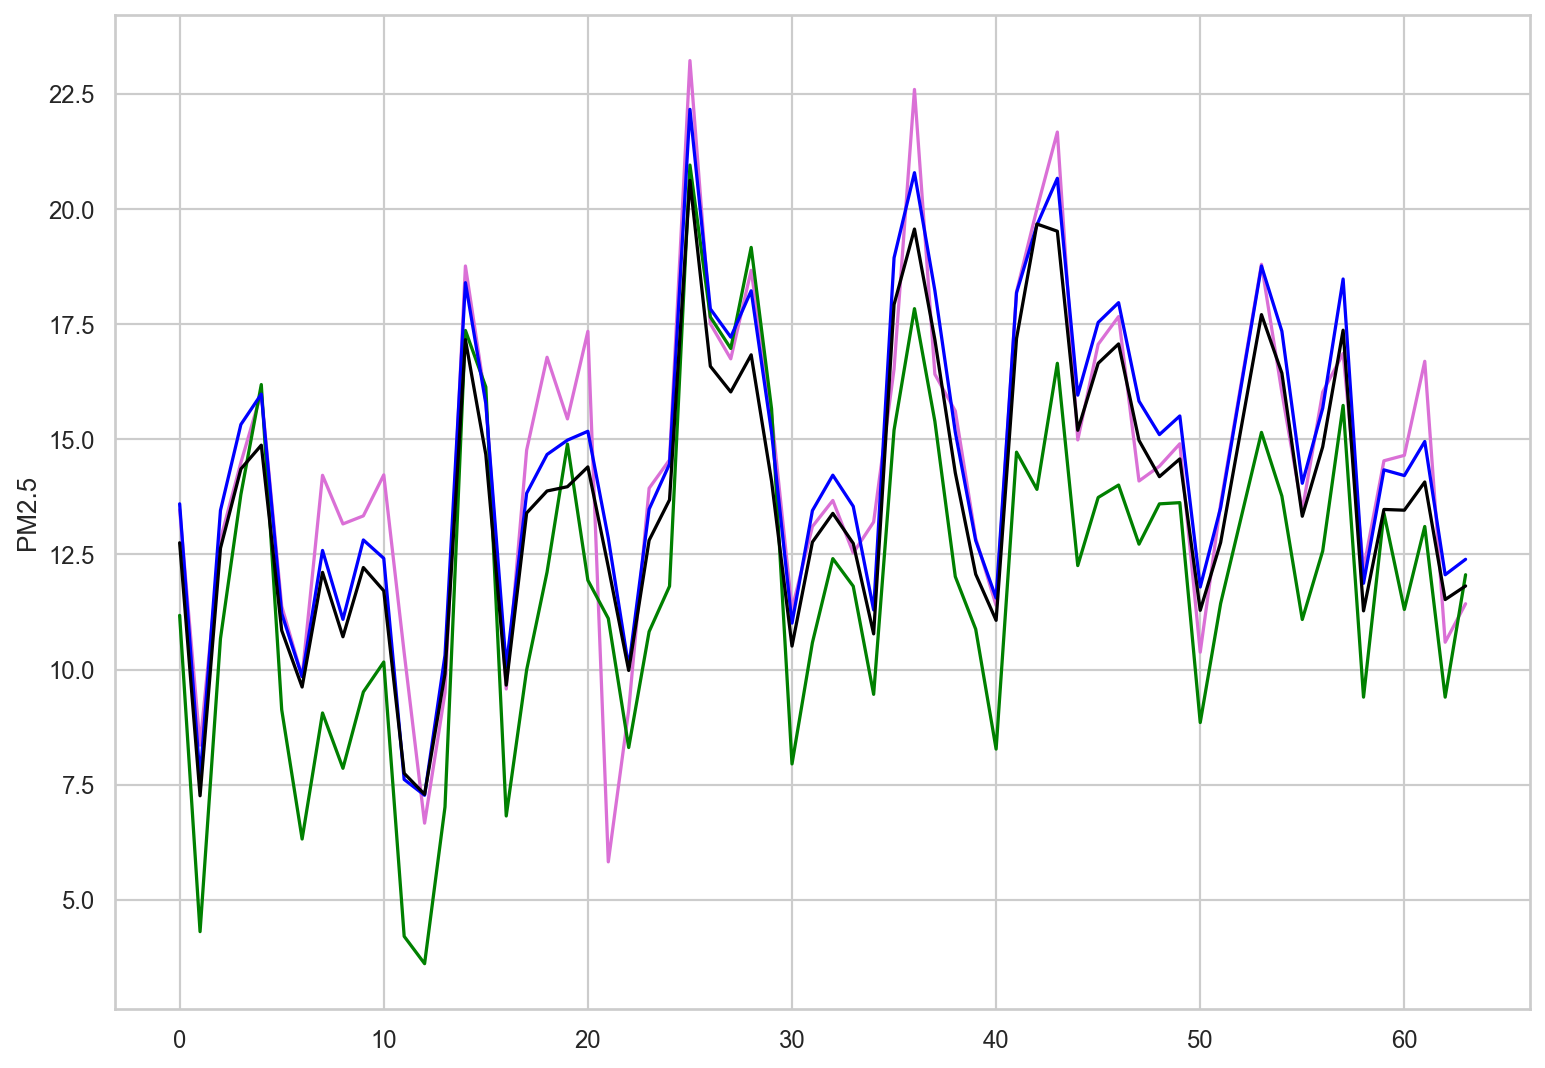

In [133]:
datos_completo = datos_dias.copy()
datos_completo['pm25corr2'] = 19.8832-0.8704*datos_completo['temperatura']+1.7063*datos_completo['hpma_pm2_5']+0.0015*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['hpma_pm2_5']-0.0403*datos_completo['humedad']*datos_completo['hpma_pm2_5']
datos_completo['pm25corr'] = 50-2.7*datos_completo['temperatura']-0.52*datos_completo['humedad']+0.5*datos_completo['hpma_pm2_5']+0.00*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['hpma_pm2_5']+0.031*datos_completo['temperatura']*datos_completo['humedad']+0.082*datos_completo['temperatura']*datos_completo['hpma_pm2_5']-0.016*datos_completo['humedad']*datos_completo['hpma_pm2_5']

sns.lineplot(data=datos_completo['PM2.5'],  color='orchid')
sns.lineplot(data=datos_completo['hpma_pm2_5'],  color='green')
sns.lineplot(data=datos_completo['pm25corr'],  color='blue')
sns.lineplot(data=datos_completo['pm25corr2'],  color='black')
# Mostrar el gráfico
plt.show()

# CO

In [154]:
datos_completo =datos_dias.copy()
datos_completo = datos_completo[['temperatura','humedad','co','CO_1']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'CO_1'
base_features = ['temperatura','humedad','co']


# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                  Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0                      temperatura, humedad, co, temperatura*humedad*co, temperatura*co  0.5366       0.4960  0.0371  0.0285
1      humedad, temperatura*humedad*co, temperatura*humedad, temperatura*co, humedad*co  0.5347       0.4939  0.0372  0.0288
2              temperatura, co, temperatura*humedad*co, temperatura*humedad, humedad*co  0.5345       0.4937  0.0372  0.0288
3                          temperatura, humedad, co, temperatura*humedad*co, humedad*co  0.5330       0.4920  0.0372  0.0288
4  temperatura, temperatura*humedad*co, temperatura*humedad, temperatura*co, humedad*co  0.5327       0.4917  0.0373  0.0289

Ecuación del mejor modelo:
b (Intersección) = -1.9686
m (Coeficientes) = {'temperatura': np.float64(0.071), 'humedad': np.float64(0.0122), 'co': np.float64(0.5434), 'temperatura*humedad*c

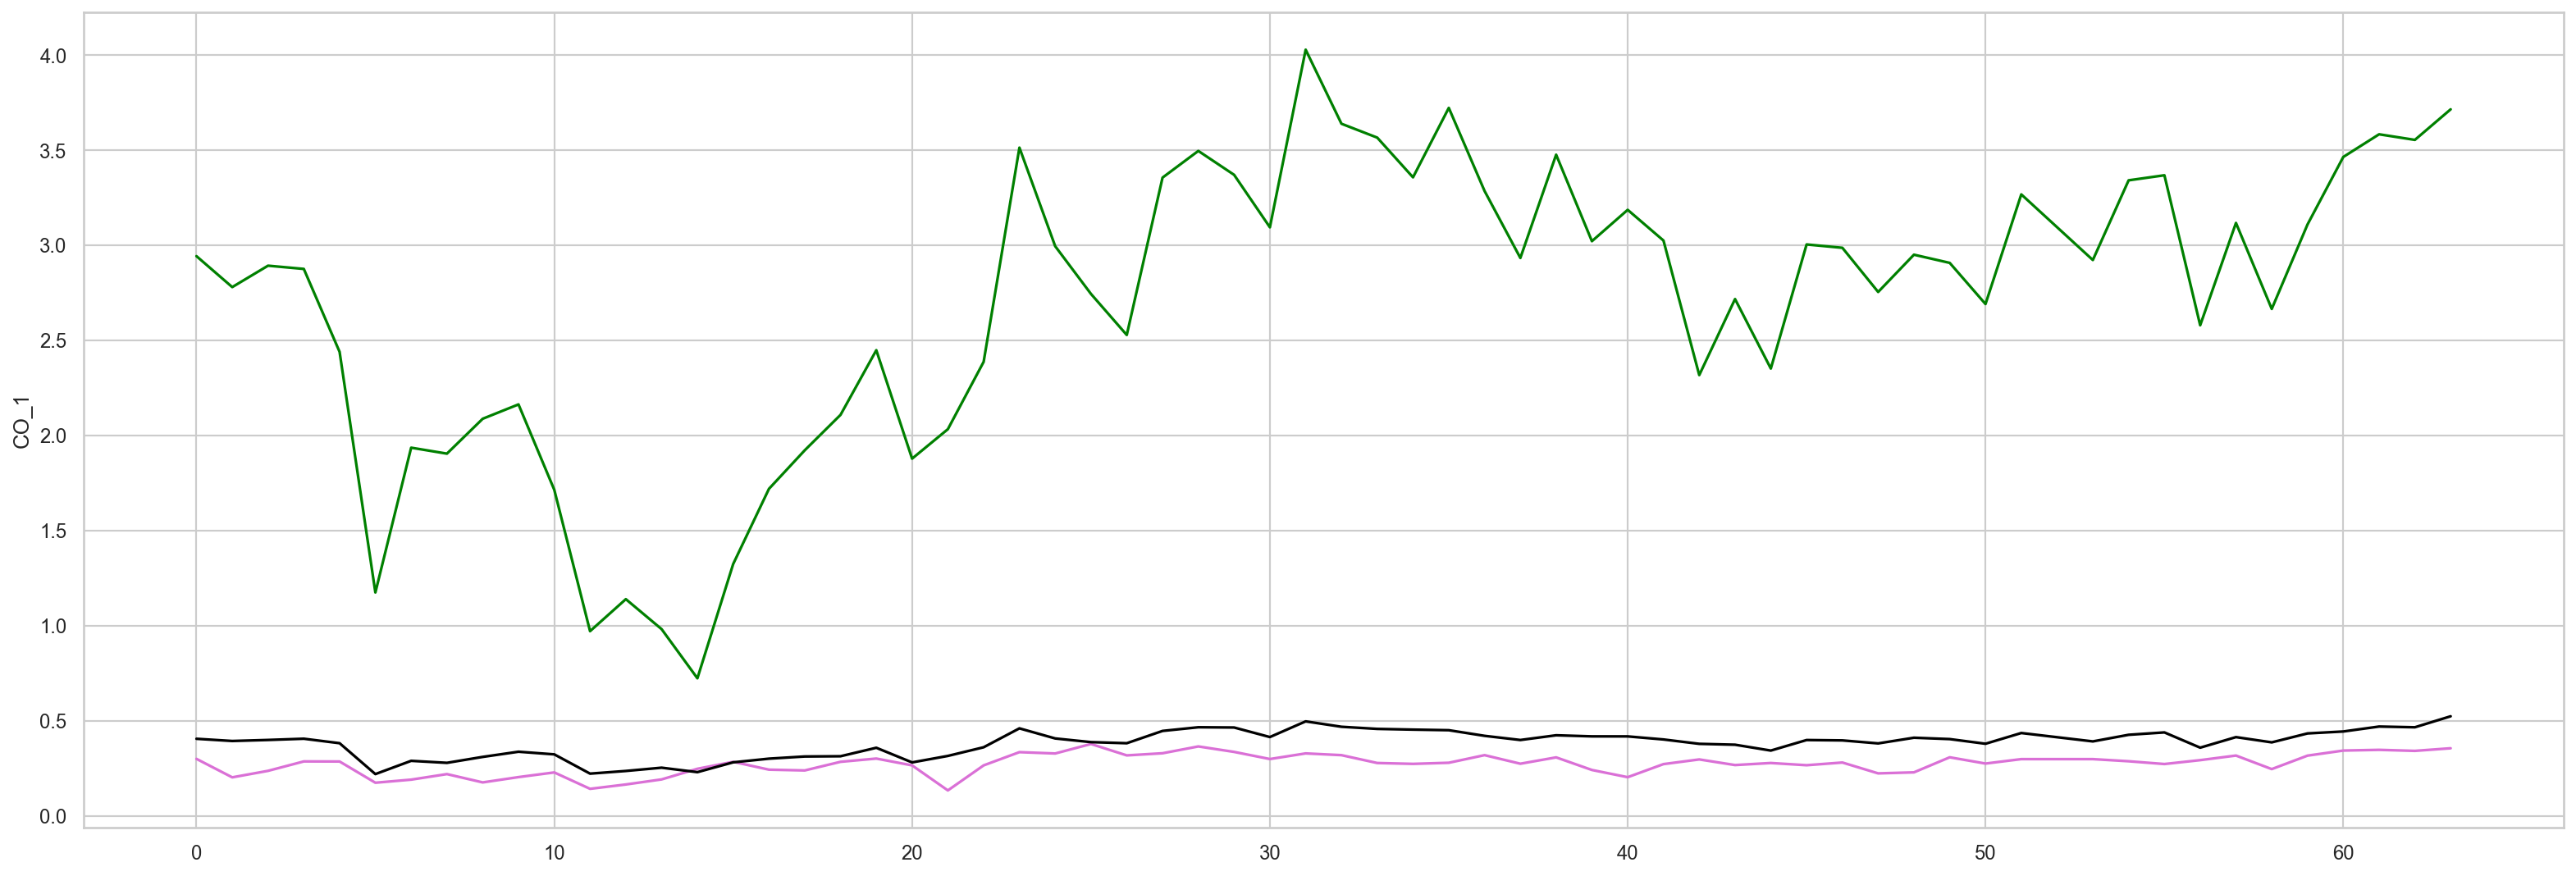

In [155]:
datos_completo = datos_dias.copy()
datos_completo['co_corr2'] = -1.9686+0.071*datos_completo['temperatura']+0.0122*datos_completo['humedad']+0.5434*datos_completo['co']-0.0002*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['co']-0.0116*datos_completo['temperatura']*datos_completo['co']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['CO_1'],  color='orchid')
sns.lineplot(ax=ax,data=datos_completo['co'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['co_corr2'],  color='black')
# Mostrar el gráfico
plt.show()

# O3

In [156]:

datos_completo = datos_completo[['temperatura','humedad','o3','O3_1']]
# 2. Definir la variable objetivo (Y) y las variables predictoras (X)
target = 'O3_1'
base_features = ['temperatura','humedad','o3']

# Generar interacciones de 3 variables (CORREGIDO)
for combo in combinations(base_features, 3):
    nombre_interaccion = f"{combo[0]}*{combo[1]}*{combo[2]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] * datos_completo[combo[2]]

# Generar interacciones de 2 variables
for combo in combinations(base_features, 2):
    nombre_interaccion = f"{combo[0]}*{combo[1]}"
    datos_completo[nombre_interaccion] = datos_completo[combo[0]] * datos_completo[combo[1]] 
    
all_features = [col for col in datos_completo.columns if col != target]

# 3. Evaluar modelos
resultados_modelos = []
n = len(datos_completo) # Número de observaciones para calcular el R2 Ajustado

for i in range(1, len(all_features) + 1):
    for combo in combinations(all_features, i):
        X = datos_completo[list(combo)]
        y = datos_completo[target]
        
        modelo = LinearRegression()
        modelo.fit(X, y)
        
        y_pred = modelo.predict(X)
        r2 = r2_score(y, y_pred)
        mae = mean_absolute_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        
        # Calcular R2 Ajustado (penaliza el exceso de variables)
        k = len(combo) # Número de variables predictoras
        # Evitar división por cero si la muestra es muy pequeña
        if n > k + 1:
            r2_adj = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
        else:
            r2_adj = r2
        
        coeficientes_dict = dict(zip(combo, np.round(modelo.coef_, 4)))
        
        resultados_modelos.append({
            'Variables_Predictoras': ', '.join(combo),
            'Cantidad_Variables': k,
            'R2': np.round(r2, 4),
            'R2_Ajustado': np.round(r2_adj, 4),
            'MAE': np.round(mae, 4),
            'RMSE': np.round(rmse, 4),
            'Interseccion_b': np.round(modelo.intercept_, 4),
            'Coeficientes_m': coeficientes_dict
        })

# 4. Ordenar por R2 Ajustado en lugar de R2 normal (esto evitará modelos sobreajustados)
datos_completo_resultados = pd.DataFrame(resultados_modelos)
datos_completo_resultados = datos_completo_resultados.sort_values(by=['R2_Ajustado', 'RMSE'], ascending=[False, True]).reset_index(drop=True)

# Imprimir resultados
print(f"Total de modelos evaluados: {len(datos_completo_resultados)}\n")
print("Top 5 mejores combinaciones:")
print(datos_completo_resultados[['Variables_Predictoras', 'R2', 'R2_Ajustado', 'RMSE', 'MAE']].head().to_string())

mejor_modelo = datos_completo_resultados.iloc[0]
print("\nEcuación del mejor modelo:")
print(f"b (Intersección) = {mejor_modelo['Interseccion_b']}")
print(f"m (Coeficientes) = {mejor_modelo['Coeficientes_m']}")

Total de modelos evaluados: 127

Top 5 mejores combinaciones:
                                                                               Variables_Predictoras      R2  R2_Ajustado    RMSE     MAE
0  temperatura, humedad, o3, temperatura*humedad*o3, temperatura*humedad, temperatura*o3, humedad*o3  0.5702       0.5155  0.0041  0.0029
1                                    humedad, o3, temperatura*humedad*o3, temperatura*o3, humedad*o3  0.5507       0.5113  0.0042  0.0031
2                                                   temperatura, o3, temperatura*humedad, humedad*o3  0.5419       0.5103  0.0042  0.0032
3                                          temperatura, humedad, o3, temperatura*humedad, humedad*o3  0.5488       0.5093  0.0042  0.0031
4                       temperatura, humedad, o3, temperatura*humedad*o3, temperatura*o3, humedad*o3  0.5558       0.5082  0.0041  0.0031

Ecuación del mejor modelo:
b (Intersección) = -0.7212
m (Coeficientes) = {'temperatura': np.float64(0.0374), 

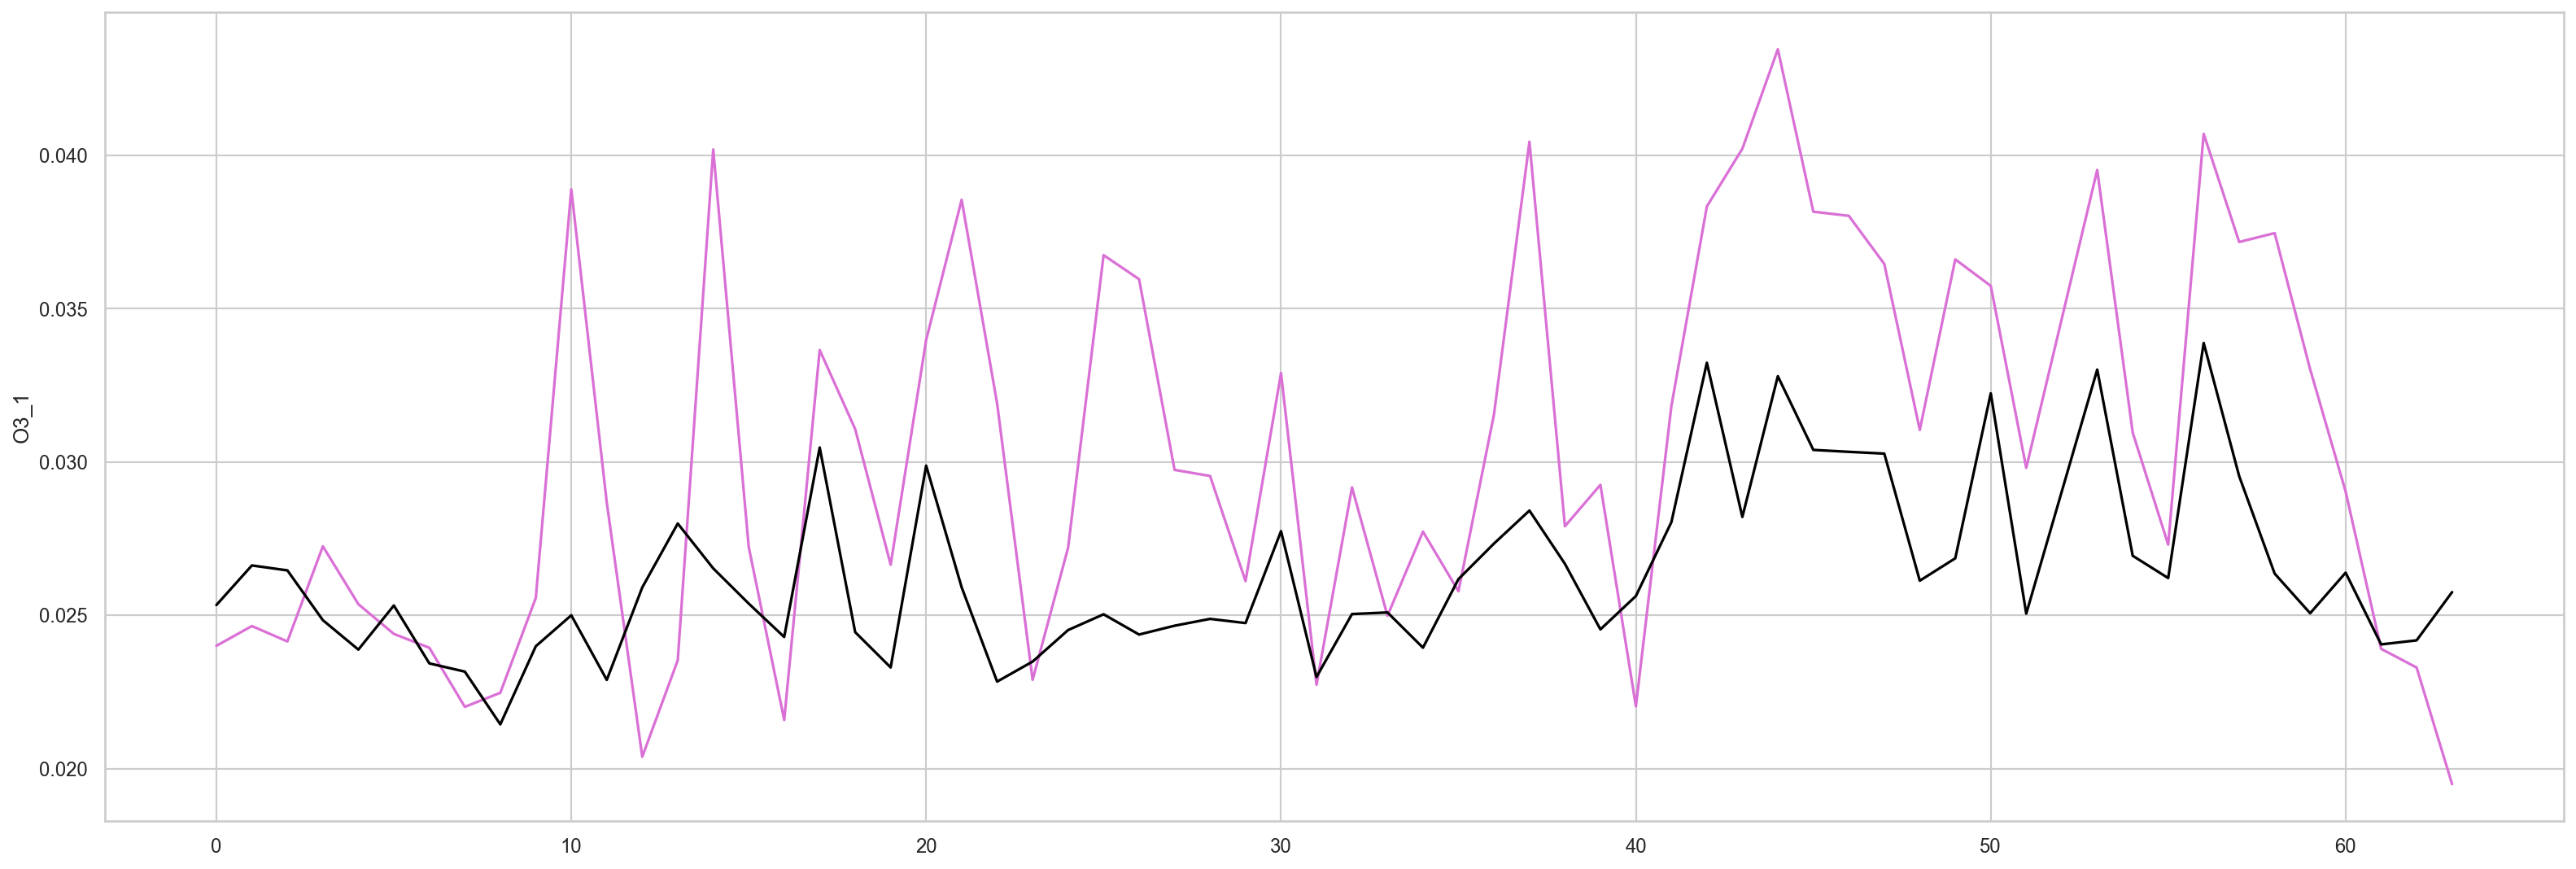

In [159]:
datos_completo = datos_dias.copy()
datos_completo['o3_corr2'] = -0.7212+0.0374*datos_completo['temperatura']+0.01*datos_completo['humedad']+1.3831*datos_completo['o3']+0.0009*datos_completo['temperatura']*datos_completo['humedad']*datos_completo['o3']-0.0005*datos_completo['temperatura']*datos_completo['humedad']-0.0663*datos_completo['temperatura']*datos_completo['o3']-0.0188*datos_completo['humedad']*datos_completo['o3']
fig, ax = plt.subplots(figsize=(25, 8.27))
sns.lineplot(ax=ax,data=datos_completo['O3_1'],  color='orchid')

#sns.lineplot(ax=ax,data=datos_completo['o3'],  color='green')
#sns.lineplot(data=datos_completo['pm25_corr'],  color='blue')
sns.lineplot(ax=ax,data=datos_completo['o3_corr2'],  color='black')
# Mostrar el gráfico
plt.show()